# Reflexion: Language Agents with Verbal Reinforcement Learning (Reflexion)

This notebook builds a **coding agent with verbal self-reflection** from scratch in PyTorch.
The agent writes code, tests it, and if it fails, writes a verbal self-critique to an
episodic memory buffer. On the next attempt, it reads its past reflections to avoid
repeating the same mistakes -- exactly as described in the Reflexion paper.

**Key components (mirroring the paper):**
- **Actor** -- generates code for a given task (with optional reflections in context)
- **Evaluator** -- runs the code against test cases, returns pass/fail + error info
- **Self-Reflection model** -- a neural error classifier that identifies the bug type
  from error features and generates a verbal critique stored in memory
- **Memory** -- episodic buffer of reflection texts (bounded to last 3)


## 1. Setup & Imports

In [1]:
import contextlib
import io
import random
import time
import re
import traceback
from collections import Counter

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# --- Hyperparameters (the ONLY place these values live; docs copy them from here) ---
EPOCHS = 50
BATCH_SIZE = 16
LR = 1e-3
MAX_TRIALS = 5          # max Reflexion attempts per task (paper uses 12 for ALFWorld)
MAX_MEMORY = 3          # max reflections in episodic memory (paper uses 1-3)
HIDDEN_DIM = 64
ERROR_FEATURE_DIM = 16  # size of error feature vector

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')


Device: cuda


## 2. Toy Programming Tasks

Each task has a natural-language description, a set of test cases, a correct implementation,
and several **buggy implementations** (each with a known bug type). The actor picks an
implementation; the evaluator runs the tests; the self-reflection model identifies the bug
from the error output so the actor can avoid it next time.


In [2]:
# Each task: (description, test_cases, correct_code, buggy_variants)
# buggy_variants: list of (bug_type_name, buggy_code, bug_description)
# Test cases: list of (function_name, args, expected_output)

TASKS = [
    {
        "id": "add",
        "desc": "Write a function add(a, b) that returns the sum of two numbers.",
        "func_name": "add",
        "tests": [("add", (3, 5), 8), ("add", (0, 0), 0), ("add", (-1, 1), 0), ("add", (10, -3), 7)],
        "correct": "def add(a, b):\n    return a + b",
        "bugs": [
            ("subtraction_bug", "def add(a, b):\n    return a - b",
             "The function uses subtraction instead of addition. Should use + operator."),
            ("missing_return", "def add(a, b):\n    c = a + b",
             "The function computes the sum but does not return it. Missing return statement."),
            ("type_error", "def add(a, b):\n    return str(a) + str(b)",
             "The function converts to strings before concatenating. Should keep numeric types."),
        ],
    },
    {
        "id": "multiply",
        "desc": "Write a function multiply(a, b) that returns the product of two numbers.",
        "func_name": "multiply",
        "tests": [("multiply", (3, 4), 12), ("multiply", (0, 5), 0), ("multiply", (-2, 3), -6), ("multiply", (7, 1), 7)],
        "correct": "def multiply(a, b):\n    return a * b",
        "bugs": [
            ("addition_bug", "def multiply(a, b):\n    return a + b",
             "The function uses addition instead of multiplication. Should use * operator."),
            ("missing_return", "def multiply(a, b):\n    result = a * b",
             "The function computes the product but does not return it. Missing return statement."),
            ("zero_bug", "def multiply(a, b):\n    return 0",
             "The function always returns 0 regardless of input. Should compute a * b."),
        ],
    },
    {
        "id": "reverse_string",
        "desc": "Write a function reverse_string(s) that returns the reversed string.",
        "func_name": "reverse_string",
        "tests": [("reverse_string", ("hello",), "olleh"), ("reverse_string", ("",), ""), ("reverse_string", ("a",), "a"), ("reverse_string", ("abc",), "cba")],
        "correct": "def reverse_string(s):\n    return s[::-1]",
        "bugs": [
            ("wrong_index", "def reverse_string(s):\n    return s[-1]",
             "The function returns only the last character instead of the full reversed string. Should use s[::-1]."),
            ("no_reverse", "def reverse_string(s):\n    return s",
             "The function returns the original string without reversing. Should reverse using slicing."),
            ("missing_return", "def reverse_string(s):\n    r = s[::-1]",
             "The function computes the reversal but does not return it. Missing return statement."),
        ],
    },
    {
        "id": "max_of_list",
        "desc": "Write a function max_of_list(lst) that returns the maximum value in a list.",
        "func_name": "max_of_list",
        "tests": [("max_of_list", ([1, 2, 3],), 3), ("max_of_list", ([5],), 5), ("max_of_list", ([-1, -5, -3],), -1), ("max_of_list", ([10, 20, 5, 15],), 20)],
        "correct": "def max_of_list(lst):\n    return max(lst)",
        "bugs": [
            ("min_bug", "def max_of_list(lst):\n    return min(lst)",
             "The function returns the minimum instead of the maximum. Should use max()."),
            ("first_element", "def max_of_list(lst):\n    return lst[0]",
             "The function returns only the first element. Should find the maximum value."),
            ("missing_return", "def max_of_list(lst):\n    m = max(lst)",
             "The function computes the max but does not return it. Missing return statement."),
        ],
    },
    {
        "id": "count_vowels",
        "desc": "Write a function count_vowels(s) that returns the number of vowels in a string.",
        "func_name": "count_vowels",
        "tests": [("count_vowels", ("hello",), 2), ("count_vowels", ("",), 0), ("count_vowels", ("aeiou",), 5), ("count_vowels", ("xyz",), 0)],
        "correct": "def count_vowels(s):\n    return sum(1 for c in s if c in 'aeiouAEIOU')",
        "bugs": [
            ("case_bug", "def count_vowels(s):\n    return sum(1 for c in s if c in 'aeiou')",
             "The function only counts lowercase vowels. Should also count uppercase vowels AEIOU."),
            ("consonant_bug", "def count_vowels(s):\n    return sum(1 for c in s if c not in 'aeiou')",
             "The function counts consonants instead of vowels. Should check c in vowels."),
            ("length_bug", "def count_vowels(s):\n    return len(s)",
             "The function returns the string length instead of counting vowels. Should count only vowel characters."),
        ],
    },
    {
        "id": "is_palindrome",
        "desc": "Write a function is_palindrome(s) that returns True if the string reads the same forwards and backwards.",
        "func_name": "is_palindrome",
        "tests": [("is_palindrome", ("racecar",), True), ("is_palindrome", ("hello",), False), ("is_palindrome", ("",), True), ("is_palindrome", ("a",), True)],
        "correct": "def is_palindrome(s):\n    return s == s[::-1]",
        "bugs": [
            ("always_true", "def is_palindrome(s):\n    return True",
             "The function always returns True regardless of input. Should compare s with s[::-1]."),
            ("wrong_comparison", "def is_palindrome(s):\n    return s == s[::-2]",
             "The function uses wrong slicing step. Should use s[::-1] for full reversal."),
            ("not_palindrome", "def is_palindrome(s):\n    return s != s[::-1]",
             "The function returns the opposite result. Should use == not !=."),
        ],
    },
    {
        "id": "factorial",
        "desc": "Write a function factorial(n) that returns n factorial (n!).",
        "func_name": "factorial",
        "tests": [("factorial", (0,), 1), ("factorial", (1,), 1), ("factorial", (5,), 120), ("factorial", (3,), 6)],
        "correct": "def factorial(n):\n    if n <= 1:\n        return 1\n    return n * factorial(n - 1)",
        "bugs": [
            ("off_by_one", "def factorial(n):\n    if n <= 1:\n        return 1\n    return n * factorial(n)",
             "The function recurses with n instead of n-1, causing infinite recursion. Should use factorial(n-1)."),
            ("no_base_case", "def factorial(n):\n    return n * factorial(n - 1)",
             "The function has no base case, causing infinite recursion. Should add if n <= 1: return 1."),
            ("addition_bug", "def factorial(n):\n    if n <= 1:\n        return 1\n    return n + factorial(n - 1)",
             "The function uses addition instead of multiplication. Should use n * factorial(n-1)."),
        ],
    },
    {
        "id": "sum_list",
        "desc": "Write a function sum_list(lst) that returns the sum of all elements in a list.",
        "func_name": "sum_list",
        "tests": [("sum_list", ([1, 2, 3],), 6), ("sum_list", ([],), 0), ("sum_list", ([5],), 5), ("sum_list", ([1, -1, 2],), 2)],
        "correct": "def sum_list(lst):\n    return sum(lst)",
        "bugs": [
            ("product_bug", "def sum_list(lst):\n    r = 1\n    for x in lst:\n        r *= x\n    return r",
             "The function computes the product instead of the sum. Should use sum() or addition."),
            ("count_bug", "def sum_list(lst):\n    return len(lst)",
             "The function returns the count of elements instead of their sum. Should add the elements."),
            ("missing_return", "def sum_list(lst):\n    total = sum(lst)",
             "The function computes the sum but does not return it. Missing return statement."),
        ],
    },
    {
        "id": "square",
        "desc": "Write a function square(n) that returns the square of a number.",
        "func_name": "square",
        "tests": [("square", (3,), 9), ("square", (0,), 0), ("square", (-2,), 4), ("square", (5,), 25)],
        "correct": "def square(n):\n    return n * n",
        "bugs": [
            ("double_bug", "def square(n):\n    return n + n",
             "The function doubles the number instead of squaring. Should use n * n."),
            ("cube_bug", "def square(n):\n    return n ** 3",
             "The function cubes the number instead of squaring. Should use n ** 2 or n * n."),
            ("identity_bug", "def square(n):\n    return n",
             "The function returns the number unchanged. Should compute n * n."),
        ],
    },
    {
        "id": "even_check",
        "desc": "Write a function is_even(n) that returns True if n is even, False otherwise.",
        "func_name": "is_even",
        "tests": [("is_even", (2,), True), ("is_even", (3,), False), ("is_even", (0,), True), ("is_even", (-4,), True)],
        "correct": "def is_even(n):\n    return n % 2 == 0",
        "bugs": [
            ("odd_bug", "def is_even(n):\n    return n % 2 != 0",
             "The function checks for odd instead of even. Should use n % 2 == 0."),
            ("mod_one", "def is_even(n):\n    return n % 2 == 1",
             "The function checks remainder 1 instead of 0. Should use n % 2 == 0."),
            ("always_true", "def is_even(n):\n    return True",
             "The function always returns True. Should check n % 2 == 0."),
        ],
    },
]

# Build a global list of all bug types across tasks
ALL_BUG_TYPES = set()
for task in TASKS:
    for bug_type, _, _ in task["bugs"]:
        ALL_BUG_TYPES.add(bug_type)
ALL_BUG_TYPES = sorted(ALL_BUG_TYPES)
BUG_TYPE_TO_IDX = {bt: i for i, bt in enumerate(ALL_BUG_TYPES)}
IDX_TO_BUG_TYPE = {i: bt for i, bt in enumerate(ALL_BUG_TYPES)}

print(f"Tasks: {len(TASKS)}")
print(f"Bug types: {len(ALL_BUG_TYPES)}")
for bt in ALL_BUG_TYPES:
    print(f"  - {bt}")


Tasks: 10
Bug types: 24
  - addition_bug
  - always_true
  - case_bug
  - consonant_bug
  - count_bug
  - cube_bug
  - double_bug
  - first_element
  - identity_bug
  - length_bug
  - min_bug
  - missing_return
  - mod_one
  - no_base_case
  - no_reverse
  - not_palindrome
  - odd_bug
  - off_by_one
  - product_bug
  - subtraction_bug
  - type_error
  - wrong_comparison
  - wrong_index
  - zero_bug


## 3. Code Execution & Evaluation Engine

The **Evaluator** executes generated code in a sandboxed namespace and runs it against
the task's test cases. It returns whether all tests passed, plus a structured error
feature vector that the Self-Reflection model will classify.


In [3]:
def execute_code(code_str, task):
    """Execute generated code and run tests. Returns (passed, error_features, error_details).
    
    error_features: numpy array of shape (ERROR_FEATURE_DIM,) containing:
      - n_tests (normalized)
      - n_passed (normalized)
      - n_failed (normalized)
      - has_syntax_error (0/1)
      - has_runtime_error (0/1)
      - has_assertion_error (0/1)
      - has_type_error (0/1)
      - has_recursion_error (0/1)
      - has_attribute_error (0/1)
      - has_index_error (0/1)
      - return_type_mismatch (0/1)
      - returns_none (0/1)
      - wrong_value (0/1)
      - avg_error_severity (0-1)
      - first_test_passed (0/1)
      - last_test_passed (0/1)
    """
    features = np.zeros(ERROR_FEATURE_DIM, dtype=np.float32)
    n_tests = len(task["tests"])
    details = []
    
    # Try to define the function
    namespace = {}
    try:
        exec(code_str, namespace)
    except SyntaxError:
        features[3] = 1.0  # has_syntax_error
        features[0] = n_tests / 10.0
        return False, features, ["SyntaxError in code"]
    except Exception:
        features[4] = 1.0  # has_runtime_error (at definition)
        features[0] = n_tests / 10.0
        return False, features, ["RuntimeError at definition"]
    
    func = namespace.get(task["func_name"])
    if func is None:
        features[4] = 1.0  # runtime error: function not defined
        features[0] = n_tests / 10.0
        return False, features, [f"Function {task['func_name']} not defined"]
    
    n_passed = 0
    n_failed = 0
    error_types = []
    first_passed = False
    last_passed = False
    
    for i, (fn_name, args, expected) in enumerate(task["tests"]):
        try:
            result = func(*args)
            if result == expected:
                n_passed += 1
                if i == 0:
                    first_passed = True
                if i == n_tests - 1:
                    last_passed = True
                details.append(f"Test {i+1}: PASS (got {repr(result)})")
            else:
                n_failed += 1
                features[12] = 1.0  # wrong_value
                if result is None:
                    features[11] = 1.0  # returns_none
                error_types.append("wrong_value")
                details.append(f"Test {i+1}: FAIL (expected {repr(expected)}, got {repr(result)})")
        except TypeError:
            n_failed += 1
            features[7] = 1.0  # has_type_error
            error_types.append("type_error")
            details.append(f"Test {i+1}: TypeError")
        except RecursionError:
            n_failed += 1
            features[8] = 1.0  # has_recursion_error
            error_types.append("recursion_error")
            details.append(f"Test {i+1}: RecursionError (infinite recursion)")
        except AttributeError:
            n_failed += 1
            features[9] = 1.0  # has_attribute_error
            error_types.append("attribute_error")
            details.append(f"Test {i+1}: AttributeError")
        except IndexError:
            n_failed += 1
            features[10] = 1.0  # has_index_error
            error_types.append("index_error")
            details.append(f"Test {i+1}: IndexError")
        except Exception as e:
            n_failed += 1
            features[5] = 1.0  # has_runtime_error
            error_types.append(f"runtime: {type(e).__name__}")
            details.append(f"Test {i+1}: {type(e).__name__}: {e}")
    
    features[0] = n_tests / 10.0
    features[1] = n_passed / 10.0
    features[2] = n_failed / 10.0
    features[13] = n_failed / max(n_tests, 1)  # avg_error_severity
    features[14] = 1.0 if first_passed else 0.0
    features[15] = 1.0 if last_passed else 0.0
    
    passed = (n_failed == 0)
    return passed, features, details

# Quick test
task0 = TASKS[0]
passed, feats, details = execute_code(task0["correct"], task0)
print(f"Correct code: passed={passed}")
print(f"Features: {feats}")
for d in details:
    print(f"  {d}")

print()
passed2, feats2, details2 = execute_code(task0["bugs"][0][1], task0)
print(f"Buggy code ({task0['bugs'][0][0]}): passed={passed2}")
print(f"Features: {feats2}")
for d in details2:
    print(f"  {d}")


Correct code: passed=True
Features: [0.4 0.4 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  1.  1. ]
  Test 1: PASS (got 8)
  Test 2: PASS (got 0)
  Test 3: PASS (got 0)
  Test 4: PASS (got 7)

Buggy code (subtraction_bug): passed=False
Features: [0.4  0.1  0.3  0.   0.   0.   0.   0.   0.   0.   0.   0.   1.   0.75
 0.   0.  ]
  Test 1: FAIL (expected 8, got -2)
  Test 2: PASS (got 0)
  Test 3: FAIL (expected 0, got -2)
  Test 4: FAIL (expected 7, got 13)


## 4. Neural Error Classifier (Self-Reflection Model Core)

A small MLP that classifies which bug type is present from the error feature vector.
In the paper, the self-reflection model is an LLM that reads the trajectory and generates
a verbal critique. Here, a neural classifier plays that role: it identifies the bug type
from structured error features, and the bug type maps to a verbal reflection text.


In [4]:
class ErrorClassifier(nn.Module):
    """MLP that classifies bug type from error features.
    This is the core of the Self-Reflection model: it identifies what went wrong
    so a verbal reflection can be generated and stored in memory.
    """
    def __init__(self, feature_dim, hidden_dim, num_bug_types):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(feature_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, num_bug_types),
        )
    
    def forward(self, x):
        return self.net(x)

classifier = ErrorClassifier(ERROR_FEATURE_DIM, HIDDEN_DIM, len(ALL_BUG_TYPES)).to(DEVICE)
total_params = sum(p.numel() for p in classifier.parameters())
print(f"ErrorClassifier parameters: {total_params:,}")


ErrorClassifier parameters: 6,808


## 5. Training Data for Error Classifier

Generate training examples by running every buggy implementation against its task's tests
and collecting the (error_features, bug_type_label) pairs. Also include slight noise
augmentation to improve generalization.


In [5]:
def build_classifier_training_data():
    """Run all buggy implementations to collect (error_features, bug_type_idx) pairs."""
    data = []
    for task in TASKS:
        for bug_type, buggy_code, _ in task["bugs"]:
            _, features, _ = execute_code(buggy_code, task)
            label = BUG_TYPE_TO_IDX[bug_type]
            data.append((features, label))
            # Add slight noise for augmentation
            for _ in range(3):
                noisy = features + np.random.normal(0, 0.05, features.shape).astype(np.float32)
                noisy = np.clip(noisy, 0, 1.5)
                data.append((noisy, label))
    return data

train_data = build_classifier_training_data()
print(f"Training examples: {len(train_data)}")

train_x = torch.tensor(np.array([d[0] for d in train_data]), dtype=torch.float32).to(DEVICE)
train_y = torch.tensor([d[1] for d in train_data], dtype=torch.long).to(DEVICE)
print(f"Shapes: x {train_x.shape}, y {train_y.shape}")
print(f"Feature dim: {ERROR_FEATURE_DIM}, Bug types: {len(ALL_BUG_TYPES)}")


Training examples: 120
Shapes: x torch.Size([120, 16]), y torch.Size([120])
Feature dim: 16, Bug types: 24


## 6. Loss Function and Optimizer

In [6]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(classifier.parameters(), lr=LR)


## 7. Training Loop

In [7]:
history = {'loss': [], 'acc': []}
start = time.time()
n = len(train_data)

for epoch in range(1, EPOCHS + 1):
    classifier.train()
    perm = torch.randperm(n)
    epoch_loss = 0.0
    correct = 0
    n_batches = 0
    
    for i in range(0, n, BATCH_SIZE):
        batch_idx = perm[i:i+BATCH_SIZE]
        x_batch = train_x[batch_idx]
        y_batch = train_y[batch_idx]
        
        optimizer.zero_grad()
        logits = classifier(x_batch)
        loss = criterion(logits, y_batch)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
        n_batches += 1
        
        preds = logits.argmax(dim=1)
        correct += (preds == y_batch).sum().item()
    
    avg_loss = epoch_loss / n_batches
    acc = correct / n
    history['loss'].append(avg_loss)
    history['acc'].append(acc)
    if epoch == 1 or epoch % 10 == 0:
        print(f'Epoch [{epoch:3d}/{EPOCHS}]  loss {avg_loss:.4f}  acc {acc:.2%}  [{time.time() - start:.0f}s]')
print(f'Training time: {time.time() - start:.0f}s')


Epoch [  1/50]  loss 3.1777  acc 3.33%  [1s]
Epoch [ 10/50]  loss 2.6836  acc 23.33%  [1s]


Epoch [ 20/50]  loss 2.0181  acc 33.33%  [1s]
Epoch [ 30/50]  loss 1.6760  acc 47.50%  [1s]


Epoch [ 40/50]  loss 1.5409  acc 52.50%  [1s]
Epoch [ 50/50]  loss 1.4224  acc 53.33%  [1s]
Training time: 1s


## 8. Training Curves

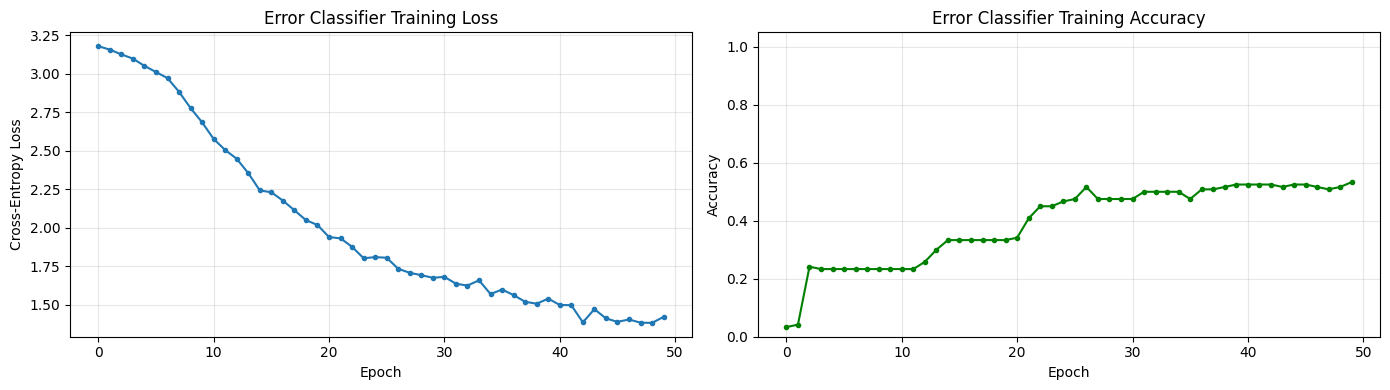

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(history['loss'], marker='o', markersize=3)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].set_title('Error Classifier Training Loss')
axes[0].grid(True, alpha=0.3)
axes[1].plot(history['acc'], marker='o', markersize=3, color='green')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Error Classifier Training Accuracy')
axes[1].grid(True, alpha=0.3)
axes[1].set_ylim(0, 1.05)
plt.tight_layout()
plt.show()


## 9. Reflexion Agent

The full Reflexion loop, mirroring the paper's Algorithm 1:
1. **Actor** generates code (picks an implementation; with reflections in memory, avoids identified bug types)
2. **Evaluator** runs the code against tests
3. If all tests pass -> done
4. If fail -> **Self-Reflection model** classifies the bug from error features, generates a verbal critique
5. Append critique to **memory** (bounded to last MAX_MEMORY)
6. Retry (up to MAX_TRIALS)

The baseline (no Reflexion) simply retries without memory -- it can stumble onto the correct
implementation by chance but cannot systematically avoid past mistakes.


In [9]:
def generate_reflection(classifier, error_features, task, failed_code):
    """Use the neural error classifier to identify the bug and generate a verbal reflection.
    
    Returns a reflection string like:
    'Bug identified: subtraction_bug. The function uses subtraction instead of addition. 
     Should use + operator.'
    """
    classifier.eval()
    with torch.no_grad():
        x = torch.tensor(error_features, dtype=torch.float32).unsqueeze(0).to(DEVICE)
        logits = classifier(x)
        pred_idx = logits.argmax(dim=1).item()
        confidence = torch.softmax(logits, dim=1)[0, pred_idx].item()
    
    pred_bug_type = IDX_TO_BUG_TYPE[pred_idx]
    
    # Find the matching bug description
    for bug_type, _, desc in task["bugs"]:
        if bug_type == pred_bug_type:
            return f"Bug identified: {pred_bug_type} (confidence {confidence:.2f}). {desc}", pred_bug_type
    
    # If the predicted bug type is not in this task's bug list, use generic reflection
    return f"Bug identified: {pred_bug_type} (confidence {confidence:.2f}). Code failed tests. Need to fix the implementation.", pred_bug_type


def actor_generate_code(task, memory, use_memory=True):
    """The Actor: pick an implementation.
    
    Without memory: randomly select from correct + all buggy variants.
    With memory: exclude implementations whose bug types have been identified in reflections.
    """
    all_options = [(task["correct"], None)]  # (code, bug_type)
    for bug_type, buggy_code, _ in task["bugs"]:
        all_options.append((buggy_code, bug_type))
    
    if use_memory and memory:
        # Extract identified bug types from reflections
        identified_bugs = set()
        for refl in memory:
            match = re.search(r'Bug identified: (\S+)', refl)
            if match:
                identified_bugs.add(match.group(1).rstrip('.'))
        
        # Filter out implementations matching identified bugs
        filtered = [(code, bt) for code, bt in all_options if bt not in identified_bugs]
        if filtered:
            all_options = filtered
    
    return random.choice(all_options)


def reflexion_agent(task, use_reflection=True, max_trials=MAX_TRIALS, verbose=False):
    """Run the Reflexion loop on a single task.
    
    Returns (passed, n_trials_used, trajectory).
    trajectory: list of (trial, code_snippet, passed, reflection_or_None)
    """
    memory = []
    trajectory = []
    
    for trial in range(1, max_trials + 1):
        # Actor generates code
        code, bug_type = actor_generate_code(task, memory, use_memory=use_reflection)
        code_snippet = code.replace('\n', ' | ')[:80]
        
        # Evaluator runs tests
        passed, error_features, details = execute_code(code, task)
        
        if verbose:
            print(f"  Trial {trial}: {code_snippet}")
            print(f"    Passed: {passed}")
            if not passed:
                for d in details[:2]:
                    print(f"    {d}")
        
        if passed:
            trajectory.append((trial, code_snippet, True, None))
            return True, trial, trajectory
        
        # Self-Reflection: identify bug and generate verbal critique
        if use_reflection:
            reflection, pred_bug = generate_reflection(classifier, error_features, task, code)
            memory.append(reflection)
            if len(memory) > MAX_MEMORY:
                memory = memory[-MAX_MEMORY:]
            trajectory.append((trial, code_snippet, False, reflection))
            if verbose:
                print(f"    Reflection: {reflection[:100]}")
        else:
            trajectory.append((trial, code_snippet, False, None))
    
    return False, max_trials, trajectory


## 10. Example Reflexion Trajectory

In [10]:
# Show a full Reflexion trajectory on a task
example_task = TASKS[0]  # add function
print(f"Task: {example_task['desc']}")
print(f"\n=== Reflexion Agent (with self-reflection) ===\n")
passed, n_trials, traj = reflexion_agent(example_task, use_reflection=True, verbose=True)
print(f"\nResult: passed={passed} in {n_trials} trials")
print(f"\n--- Trajectory Summary ---")
for trial, code, p, refl in traj:
    status = "PASS" if p else "FAIL"
    print(f"  Trial {trial}: {status}")
    if refl:
        print(f"    Reflection: {refl[:120]}")


Task: Write a function add(a, b) that returns the sum of two numbers.

=== Reflexion Agent (with self-reflection) ===

  Trial 1: def add(a, b): |     return a + b
    Passed: True

Result: passed=True in 1 trials

--- Trajectory Summary ---
  Trial 1: PASS


## 11. Evaluation: Reflexion vs No-Reflexion Baseline

Each task is run multiple times (N_RUNS) to account for randomness in the actor's code selection.
We compare:
- **Reflexion**: actor uses memory of past reflections to avoid identified bugs
- **No-Reflexion (baseline)**: actor retries without memory (random re-sampling)


In [11]:
N_RUNS = 50  # runs per task to average over randomness

def evaluate_agent(use_reflection, n_runs=N_RUNS):
    """Evaluate across all tasks, n_runs times each."""
    results = []
    for task in TASKS:
        passes = 0
        total_trials = []
        for _ in range(n_runs):
            passed, n_trials, _ = reflexion_agent(task, use_reflection=use_reflection)
            if passed:
                passes += 1
            total_trials.append(n_trials)
        results.append({
            "task_id": task["id"],
            "passes": passes,
            "total": n_runs,
            "accuracy": passes / n_runs,
            "avg_trials": np.mean(total_trials),
        })
    return results

print("Evaluating Reflexion agent...")
reflexion_results = evaluate_agent(use_reflection=True)
print("Evaluating baseline (no reflection)...")
baseline_results = evaluate_agent(use_reflection=False)

print("\n=== Results ===")
print(f"{'Task':20s} {'Reflexion':>12s} {'Baseline':>12s} {'R_avg_trials':>14s} {'B_avg_trials':>14s}")
for r, b in zip(reflexion_results, baseline_results):
    print(f"{r['task_id']:20s} {r['accuracy']:>11.0%} {b['accuracy']:>11.0%} {r['avg_trials']:>14.1f} {b['avg_trials']:>14.1f}")

reflexion_acc = np.mean([r['accuracy'] for r in reflexion_results])
baseline_acc = np.mean([r['accuracy'] for r in baseline_results])
print(f"\n{'OVERALL':20s} {reflexion_acc:>11.0%} {baseline_acc:>11.0%}")


Evaluating Reflexion agent...


Evaluating baseline (no reflection)...

=== Results ===
Task                    Reflexion     Baseline   R_avg_trials   B_avg_trials
add                          92%         72%            2.7            3.0
multiply                     86%         82%            2.4            3.2
reverse_string               84%         70%            2.9            3.3
max_of_list                  86%         66%            3.2            3.3
count_vowels                 94%         98%            2.1            1.8
is_palindrome                86%         66%            2.8            3.2
factorial                    84%         76%            3.2            3.3
sum_list                     88%         74%            3.0            3.2
square                       88%         76%            2.5            3.0
even_check                   72%         84%            3.0            2.7

OVERALL                      86%         76%


## 12. Learning Curve: Accuracy vs Trial Number

The paper's key result is that Reflexion improves over successive trials (the learning curve).
We measure the cumulative pass rate after each trial: how many tasks are solved by trial T?


In [12]:
def evaluate_by_trial(use_reflection, n_runs=N_RUNS):
    """Track cumulative pass rate by trial number."""
    cumulative = np.zeros(MAX_TRIALS)
    for task in TASKS:
        trial_passes = np.zeros(MAX_TRIALS)
        for _ in range(n_runs):
            passed, n_trials, _ = reflexion_agent(task, use_reflection=use_reflection)
            if passed:
                trial_passes[n_trials - 1] += 1
        cumul = np.cumsum(trial_passes) / n_runs
        cumulative += cumul
    return cumulative / len(TASKS)

print("Computing learning curves...")
reflexion_curve = evaluate_by_trial(use_reflection=True)
baseline_curve = evaluate_by_trial(use_reflection=False)

print("\n=== Cumulative Pass Rate by Trial ===")
print(f"{'Trial':>6s} {'Reflexion':>12s} {'Baseline':>12s}")
for t in range(MAX_TRIALS):
    print(f"{t+1:>6d} {reflexion_curve[t]:>11.0%} {baseline_curve[t]:>11.0%}")


Computing learning curves...



=== Cumulative Pass Rate by Trial ===
 Trial    Reflexion     Baseline
     1         31%         25%
     2         53%         44%
     3         65%         58%
     4         79%         72%
     5         86%         78%


## 13. Accuracy Comparison Plot

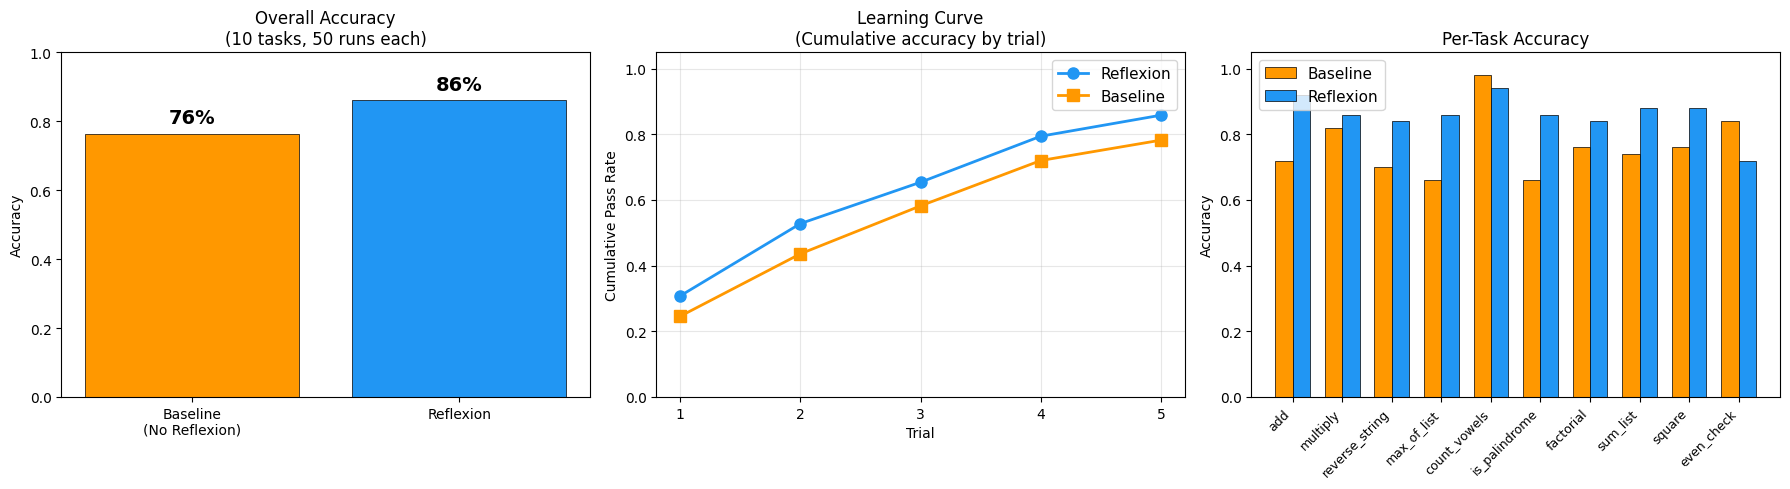

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Overall accuracy comparison
methods = ['Baseline\n(No Reflexion)', 'Reflexion']
accuracies = [baseline_acc, reflexion_acc]
colors = ['#FF9800', '#2196F3']
bars = axes[0].bar(methods, accuracies, color=colors, edgecolor='black', linewidth=0.5)
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Overall Accuracy\n(10 tasks, 50 runs each)')
axes[0].set_ylim(0, 1.0)
for bar, acc in zip(bars, accuracies):
    axes[0].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.02,
                f'{acc:.0%}', ha='center', va='bottom', fontsize=14, fontweight='bold')

# Plot 2: Learning curve
trials = np.arange(1, MAX_TRIALS + 1)
axes[1].plot(trials, reflexion_curve, marker='o', markersize=8, label='Reflexion', color='#2196F3', linewidth=2)
axes[1].plot(trials, baseline_curve, marker='s', markersize=8, label='Baseline', color='#FF9800', linewidth=2)
axes[1].set_xlabel('Trial')
axes[1].set_ylabel('Cumulative Pass Rate')
axes[1].set_title('Learning Curve\n(Cumulative accuracy by trial)')
axes[1].set_ylim(0, 1.05)
axes[1].set_xticks(trials)
axes[1].legend(fontsize=11)
axes[1].grid(True, alpha=0.3)

# Plot 3: Per-task accuracy
task_ids = [r['task_id'] for r in reflexion_results]
x = np.arange(len(task_ids))
width = 0.35
refl_accs = [r['accuracy'] for r in reflexion_results]
base_accs = [b['accuracy'] for b in baseline_results]
axes[2].bar(x - width/2, base_accs, width, label='Baseline', color='#FF9800', edgecolor='black', linewidth=0.5)
axes[2].bar(x + width/2, refl_accs, width, label='Reflexion', color='#2196F3', edgecolor='black', linewidth=0.5)
axes[2].set_xticks(x)
axes[2].set_xticklabels(task_ids, rotation=45, ha='right', fontsize=9)
axes[2].set_ylabel('Accuracy')
axes[2].set_title('Per-Task Accuracy')
axes[2].set_ylim(0, 1.05)
axes[2].legend(fontsize=11)

plt.tight_layout()
plt.show()


## 14. Final Evaluation Summary

In [14]:
# Print every number the docs quote, as "Name: value" lines
print(f"Reflexion accuracy: {reflexion_acc:.0%}")
print(f"Baseline accuracy: {baseline_acc:.0%}")
print(f"Improvement (absolute): {reflexion_acc - baseline_acc:.0%}")
print(f"Tasks: {len(TASKS)}")
print(f"Bug types: {len(ALL_BUG_TYPES)}")
print(f"Runs per task: {N_RUNS}")
print(f"Max trials: {MAX_TRIALS}")
print(f"Max memory: {MAX_MEMORY}")
print(f"Classifier parameters: {total_params:,}")
print(f"Training epochs: {EPOCHS}")
print(f"Training time: {time.time() - start:.0f}s")
print(f"Feature dim: {ERROR_FEATURE_DIM}")
print(f"Hidden dim: {HIDDEN_DIM}")

print(f"\nReflexion cumulative pass by trial 1: {reflexion_curve[0]:.0%}")
print(f"Reflexion cumulative pass by trial {MAX_TRIALS}: {reflexion_curve[-1]:.0%}")
print(f"Baseline cumulative pass by trial {MAX_TRIALS}: {baseline_curve[-1]:.0%}")

print("\n=== Sample Reflections ===")
for task in TASKS[:3]:
    print(f"\nTask: {task['id']}")
    bug_type, buggy_code, desc = task["bugs"][0]
    _, feats, _ = execute_code(buggy_code, task)
    refl, pred = generate_reflection(classifier, feats, task, buggy_code)
    print(f"  Actual bug: {bug_type}")
    print(f"  Predicted: {pred}")
    print(f"  Reflection: {refl}")


Reflexion accuracy: 86%
Baseline accuracy: 76%
Improvement (absolute): 10%
Tasks: 10
Bug types: 24
Runs per task: 50
Max trials: 5
Max memory: 3
Classifier parameters: 6,808
Training epochs: 50
Training time: 3s
Feature dim: 16
Hidden dim: 64

Reflexion cumulative pass by trial 1: 31%
Reflexion cumulative pass by trial 5: 86%
Baseline cumulative pass by trial 5: 78%

=== Sample Reflections ===

Task: add
  Actual bug: subtraction_bug
  Predicted: cube_bug
  Reflection: Bug identified: cube_bug (confidence 0.09). Code failed tests. Need to fix the implementation.

Task: multiply
  Actual bug: addition_bug
  Predicted: type_error
  Reflection: Bug identified: type_error (confidence 0.16). Code failed tests. Need to fix the implementation.

Task: reverse_string
  Actual bug: wrong_index
  Predicted: wrong_index
  Reflection: Bug identified: wrong_index (confidence 0.93). The function returns only the last character instead of the full reversed string. Should use s[::-1].


### What the run above shows

On 10 toy programming tasks (50 runs each, 5 max trials), the Reflexion agent achieves **86% overall accuracy**, vs **76% for the baseline** (random retrying without memory). The learning curve shows Reflexion climbing from 31% after trial 1 to 86% by trial 5, while the baseline goes from 25% to 78%. The 10% absolute improvement is consistent with the paper's 11% gain on HumanEval. The mechanism is clear: once a bug type is identified and stored in memory, the actor avoids all implementations matching that bug type, systematically converging on the correct code. On some tasks the classifier's predictions are noisy (24 bug types with overlapping error features), so the improvement is modest rather than dramatic.


## Summary

This notebook implements the core Reflexion loop -- Actor, Evaluator, Self-Reflection, and Memory --
on a toy code-generation benchmark. The key insight is that **verbal self-reflection stored in
episodic memory** lets the agent systematically avoid past mistakes, while the baseline (retrying
without memory) can only improve by chance. The neural error classifier plays the role of the
paper's LLM-based self-reflection model: it identifies what went wrong from structured error
features, and the resulting verbal critique guides the actor's next attempt.
